# Student Performance Prediction

### Machine Learning Classification Project

**Dataset:** Student Performance Factors

## Project Overview
This project analyzes student performance using academic, behavioral,
educational, and environmental factors.

## Objectives
- Analyze exam score distribution.
- Study the impact of study habits on exam performance.
- Analyze previous scores and current exam scores.
- Explore educational support and learning environment factors.
- Build and compare Machine Learning classification models.

## Algorithms Used
1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Gaussian Naive Bayes
4. Random Forest Classifier

## Technologies Used
Python, Pandas, NumPy, Matplotlib, and Scikit-learn.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Loading the Dataset

In this step, we load the Student Performance Factors dataset using Pandas.

The dataset contains information about students' study habits, educational
support, learning environment, and exam scores.

In [3]:
df = pd.read_csv(
    r"C:\Users\sohga\Downloads\StudentPerformanceFactors.csv"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (6607, 20)


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


## 2. Understanding the Dataset

In this step, we examine the dataset structure, column names, data types,
and statistical summary to understand the available student information.

In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Shape: (6607, 20)

Column Names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Prev

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
count,6607.000000,6607.000000,6607,6607,6607,6607.00000,6607.000000,6607,6607,6607.000000,6607,6529,6607,6607,6607.000000,6607,6517,6540,6607,6607.000000
unique,NaN,NaN,3,3,2,NaN,NaN,3,2,NaN,3,3,2,3,NaN,2,3,3,2,NaN
top,NaN,NaN,Medium,Medium,Yes,NaN,NaN,Medium,Yes,NaN,Low,Medium,Public,Positive,NaN,No,High School,Near,Male,NaN
freq,NaN,NaN,3362,3319,3938,NaN,NaN,3351,6108,NaN,2672,3925,4598,2638,NaN,5912,3223,3884,3814,NaN
mean,19.975329,79.977448,NaN,NaN,NaN,7.02906,75.070531,NaN,NaN,1.493719,NaN,NaN,NaN,NaN,2.967610,NaN,NaN,NaN,NaN,67.235659
std,5.990594,11.547475,NaN,NaN,NaN,1.46812,14.399784,NaN,NaN,1.230570,NaN,NaN,NaN,NaN,1.031231,NaN,NaN,NaN,NaN,3.890456
min,1.000000,60.000000,NaN,NaN,NaN,4.00000,50.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,55.000000
25%,16.000000,70.000000,NaN,NaN,NaN,6.00000,63.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,65.000000
50%,20.000000,80.000000,NaN,NaN,NaN,7.00000,75.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,3.000000,NaN,NaN,NaN,NaN,67.000000
75%,24.000000,90.000000,NaN,NaN,NaN,8.00000,88.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,69.000000


## 3. Checking Missing Values and Duplicates

In this step, we identify missing values and duplicate records
before performing data cleaning.

In [5]:
print("Missing Values in Each Column:")
display(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values in Each Column:


Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64


Total Missing Values: 235

Duplicate Rows: 0


## 4. Data Cleaning

In this step, duplicate records are removed and missing values are handled.

- Categorical columns: Missing values are filled with the mode.
- Numerical columns: Missing values are filled with the median.

In [7]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Handle missing values
for column in df.columns:

    if df[column].isnull().any():

        # Numeric columns: fill missing values with median
        if pd.api.types.is_numeric_dtype(df[column]):
            df[column] = df[column].fillna(df[column].median())

        # Categorical columns: fill missing values with mode
        else:
            mode_values = df[column].mode()

            if not mode_values.empty:
                df[column] = df[column].fillna(mode_values[0])

print("Data cleaning completed!")

print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Data cleaning completed!
Dataset shape: (6607, 20)
Total missing values: 0
Duplicate rows: 0


## 5. Statistical Analysis of Exam Scores

In this section, we calculate descriptive statistics for students' exam scores.

We analyze the mean, median, minimum, maximum, and standard deviation
to understand the distribution and variability of exam performance.

In [8]:
print("EXAM SCORE STATISTICAL ANALYSIS")

print("Mean Score:", round(df["Exam_Score"].mean(), 2))
print("Median Score:", df["Exam_Score"].median())
print("Minimum Score:", df["Exam_Score"].min())
print("Maximum Score:", df["Exam_Score"].max())
print("Standard Deviation:", round(df["Exam_Score"].std(), 2))

EXAM SCORE STATISTICAL ANALYSIS
Mean Score: 67.24
Median Score: 67.0
Minimum Score: 55
Maximum Score: 101
Standard Deviation: 3.89


## 6. Distribution of Exam Scores

A histogram shows how frequently different exam scores occur.

It helps us understand the spread and concentration of students' scores.

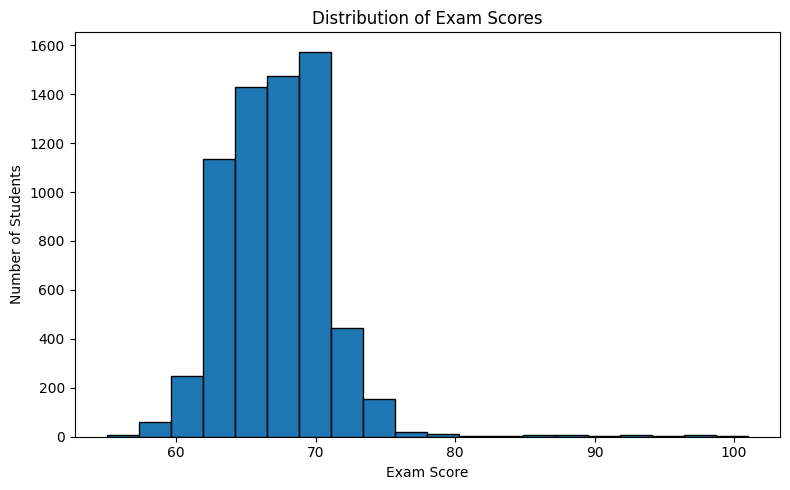

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(df["Exam_Score"], bins=20, edgecolor="black")

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

## 7. Boxplot of Exam Scores

A boxplot summarizes the distribution of exam scores and helps identify
the median, spread, and potential outliers.

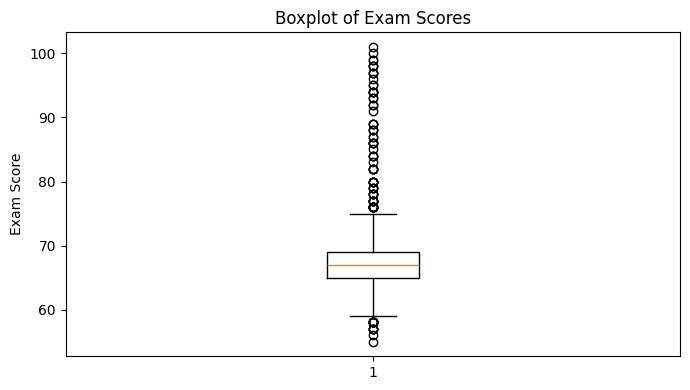

In [10]:
plt.figure(figsize=(7, 4))

plt.boxplot(df["Exam_Score"])

plt.title("Boxplot of Exam Scores")
plt.ylabel("Exam Score")

plt.tight_layout()
plt.show()

## 8. Study Habits and Exam Performance

In this section, we analyze the relationship between study habits
and students' exam scores.

The following factors are considered:
- Hours Studied
- Attendance
- Sleep Hours
- Physical Activity

Correlation analysis is used to examine relationships between
numerical variables.

In [11]:
study_columns = [
    "Hours_Studied",
    "Attendance",
    "Sleep_Hours",
    "Physical_Activity"
]

print("Correlation Between Study Habits and Exam Scores:")

display(
    df[study_columns + ["Exam_Score"]]
    .corr(numeric_only=True)
)

Correlation Between Study Habits and Exam Scores:


,Hours_Studied,Attendance,Sleep_Hours,Physical_Activity,Exam_Score
Hours_Studied,1.000000,-0.009908,0.010977,0.004624,0.445455
Attendance,-0.009908,1.000000,-0.015918,-0.022435,0.581072
Sleep_Hours,0.010977,-0.015918,1.000000,-0.000378,-0.017022
Physical_Activity,0.004624,-0.022435,-0.000378,1.000000,0.027824
Exam_Score,0.445455,0.581072,-0.017022,0.027824,1.000000


## 9. Visual Analysis of Study Habits

Scatter plots are created to visualize the relationship between
each study habit and exam scores.

These plots help us identify possible patterns and trends.

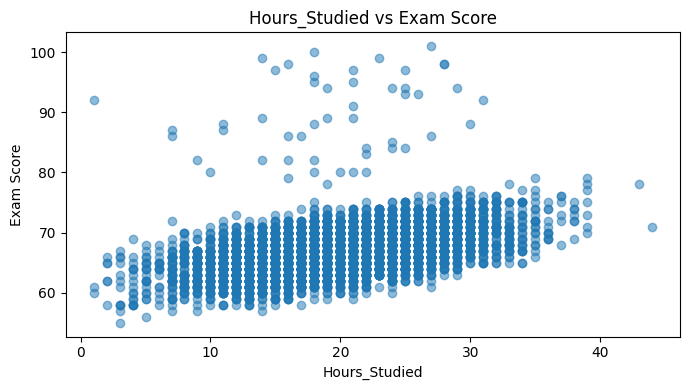

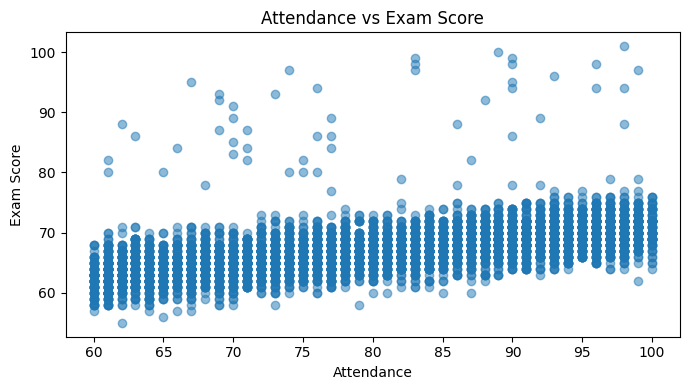

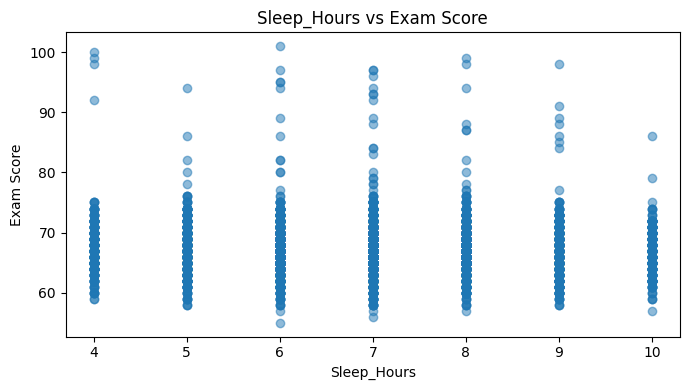

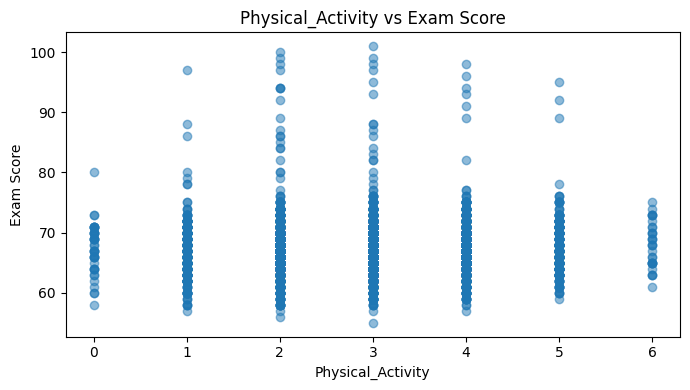

In [12]:
for column in study_columns:

    plt.figure(figsize=(7, 4))

    plt.scatter(
        df[column],
        df["Exam_Score"],
        alpha=0.5
    )

    plt.title(f"{column} vs Exam Score")
    plt.xlabel(column)
    plt.ylabel("Exam Score")

    plt.tight_layout()
    plt.show()

## 10. Previous Scores and Current Exam Performance

In this section, we examine the relationship between previous scores
and current exam scores using correlation analysis and a scatter plot.

Correlation between Previous Scores and Exam Scores: 0.175


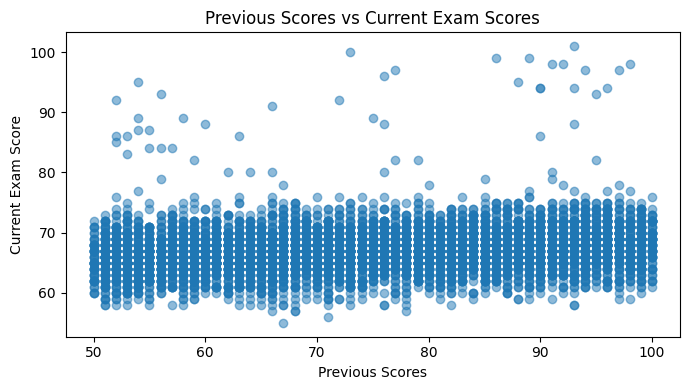

In [13]:
correlation = df["Previous_Scores"].corr(df["Exam_Score"])

print(
    "Correlation between Previous Scores and Exam Scores:",
    round(correlation, 3)
)

plt.figure(figsize=(7, 4))

plt.scatter(
    df["Previous_Scores"],
    df["Exam_Score"],
    alpha=0.5
)

plt.title("Previous Scores vs Current Exam Scores")
plt.xlabel("Previous Scores")
plt.ylabel("Current Exam Score")

plt.tight_layout()
plt.show()

## 11. Educational Support and Exam Performance

This section analyzes the relationship between educational support
factors and students' exam scores.

The factors include:
- Parental Involvement
- Access to Resources
- Teacher Quality
- Tutoring Sessions

We calculate the average exam score for each category and visualize
the results using bar charts.


Average Exam Score by Parental_Involvement:


Parental_Involvement
High      68.09
Medium    67.10
Low       66.36
Name: Exam_Score, dtype: float64

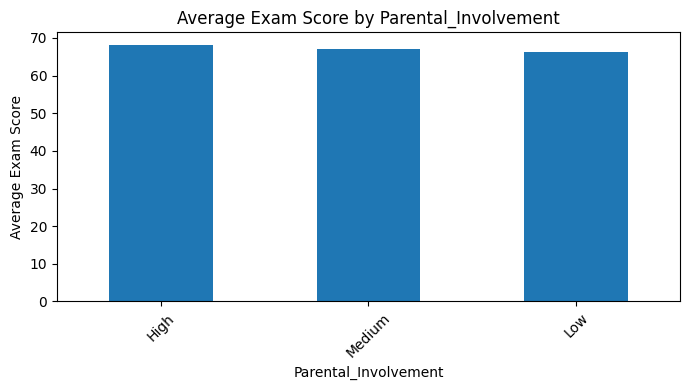


Average Exam Score by Access_to_Resources:


Access_to_Resources
High      68.09
Medium    67.13
Low       66.20
Name: Exam_Score, dtype: float64

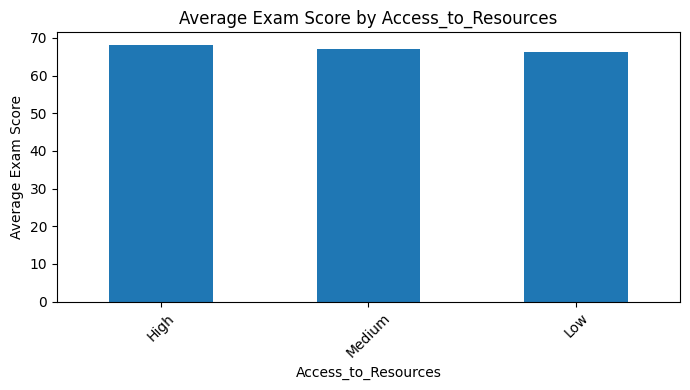


Average Exam Score by Teacher_Quality:


Teacher_Quality
High      67.68
Medium    67.10
Low       66.75
Name: Exam_Score, dtype: float64

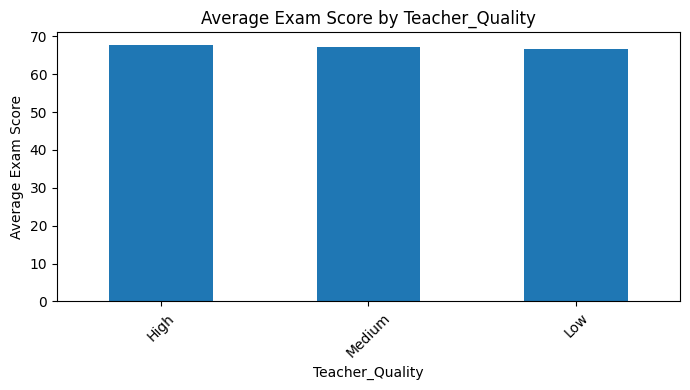


Average Exam Score by Tutoring_Sessions:


Tutoring_Sessions
6    71.67
7    69.86
5    69.07
8    69.00
4    68.23
3    67.89
2    67.57
1    66.98
0    66.49
Name: Exam_Score, dtype: float64

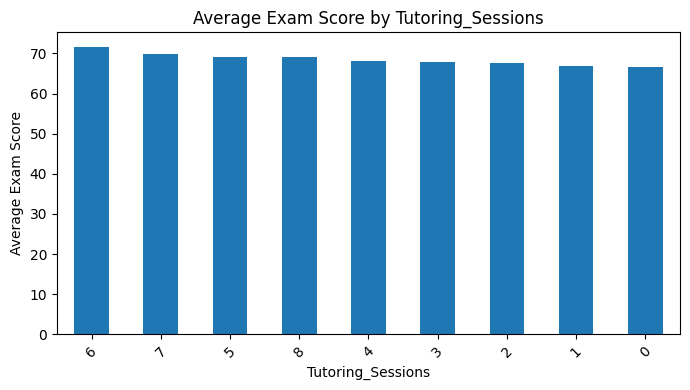

In [14]:
support_columns = [
    "Parental_Involvement",
    "Access_to_Resources",
    "Teacher_Quality",
    "Tutoring_Sessions"
]

for column in support_columns:

    average_scores = (
        df.groupby(column)["Exam_Score"]
        .mean()
        .sort_values(ascending=False)
    )

    print(f"\nAverage Exam Score by {column}:")
    display(average_scores.round(2))

    average_scores.plot(kind="bar", figsize=(7, 4))

    plt.title(f"Average Exam Score by {column}")
    plt.xlabel(column)
    plt.ylabel("Average Exam Score")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 12. Learning Environment and Exam Performance

This section examines how learning environment factors are associated
with students' exam scores.

The factors include:
- Internet Access
- School Type
- Family Income
- Peer Influence
- Motivation Level

We compare average exam scores across different categories using
grouped analysis and bar charts.


Average Exam Score by Internet_Access:


Internet_Access
Yes    67.29
No     66.54
Name: Exam_Score, dtype: float64

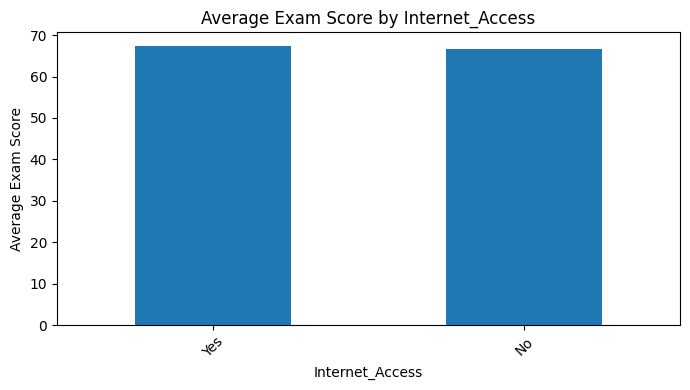


Average Exam Score by School_Type:


School_Type
Private    67.29
Public     67.21
Name: Exam_Score, dtype: float64

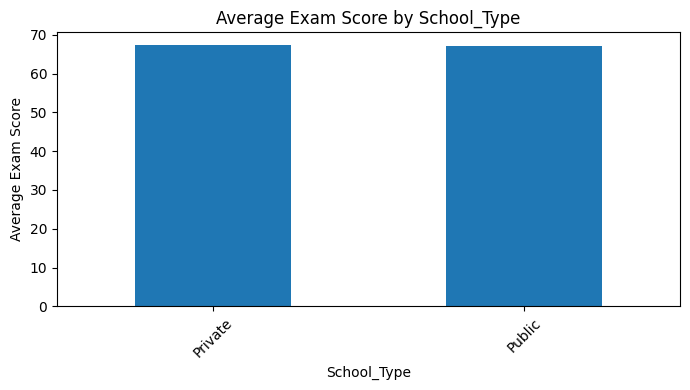


Average Exam Score by Family_Income:


Family_Income
High      67.84
Medium    67.33
Low       66.85
Name: Exam_Score, dtype: float64

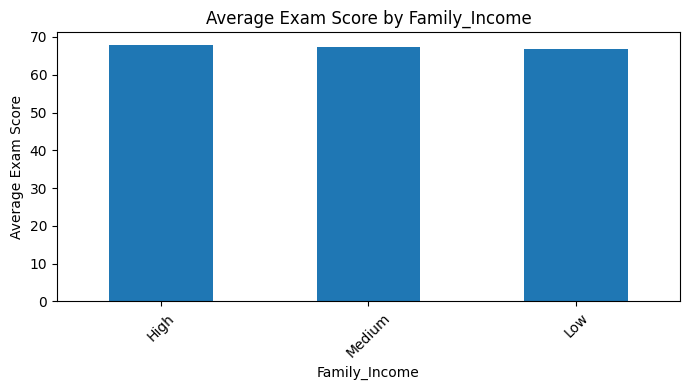


Average Exam Score by Peer_Influence:


Peer_Influence
Positive    67.62
Neutral     67.20
Negative    66.56
Name: Exam_Score, dtype: float64

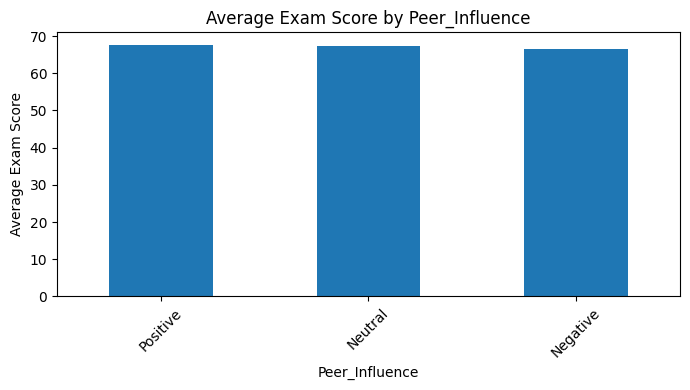


Average Exam Score by Motivation_Level:


Motivation_Level
High      67.70
Medium    67.33
Low       66.75
Name: Exam_Score, dtype: float64

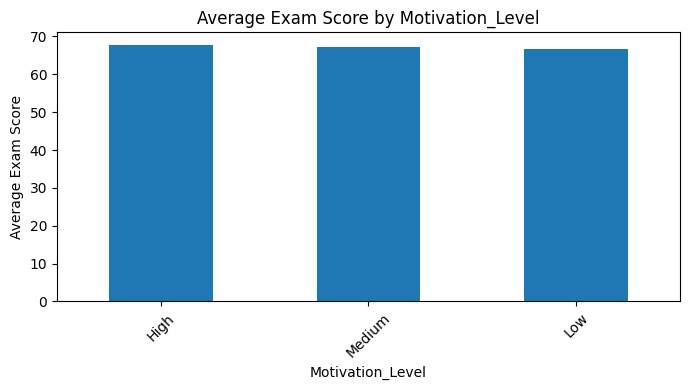

In [15]:
environment_columns = [
    "Internet_Access",
    "School_Type",
    "Family_Income",
    "Peer_Influence",
    "Motivation_Level"
]

for column in environment_columns:

    average_scores = (
        df.groupby(column)["Exam_Score"]
        .mean()
        .sort_values(ascending=False)
    )

    print(f"\nAverage Exam Score by {column}:")
    display(average_scores.round(2))

    average_scores.plot(kind="bar", figsize=(7, 4))

    plt.title(f"Average Exam Score by {column}")
    plt.xlabel(column)
    plt.ylabel("Average Exam Score")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## 13. Creating Student Performance Levels

For classification, we convert numerical exam scores into three
project-defined categories:

- Low: Exam score less than or equal to 64
- Medium: Exam score between 65 and 69
- High: Exam score greater than or equal to 70

These categories are created for this project and are not official
academic grades.

In [16]:
df["Performance_Level"] = pd.cut(
    df["Exam_Score"],
    bins=[-np.inf, 64, 69, np.inf],
    labels=["Low", "Medium", "High"]
)

print("Performance Level Counts:")
display(df["Performance_Level"].value_counts())

print("\nPerformance Level Percentages:")
display(
    (df["Performance_Level"].value_counts(normalize=True) * 100)
    .round(2)
)

Performance Level Counts:


Performance_Level
Medium    3530
High      1625
Low       1452
Name: count, dtype: int64


Performance Level Percentages:


Performance_Level
Medium    53.43
High      24.60
Low       21.98
Name: proportion, dtype: float64

## 14. Feature Selection and Target Variable

In this step, we separate the input features (X) and target variable (y).

- X contains student-related factors used for prediction.
- y contains the Performance_Level that we want to predict.

Exam_Score is removed from X because Performance_Level is created
directly from Exam_Score. Including it would cause data leakage.

In [17]:
# Separate input features and target variable
X = df.drop(["Exam_Score", "Performance_Level"], axis=1)

y = df["Performance_Level"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(y.value_counts())

Features shape: (6607, 19)
Target shape: (6607,)

Input Features:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Target Classes:
Performance_Level
Medium    3530
High      1625
Low       1452
Name: count, dtype: int64


## 15. Encoding Categorical Variables

Machine Learning algorithms require numerical input.

We use LabelEncoder to convert categorical text values into numerical
labels so that the models can process them.

In [22]:
# Create a copy of the features
X_encoded = X.copy()

# Store encoders for categorical columns
label_encoders = {}

for column in X_encoded.columns:

    # Detect text and categorical columns
    if (
        pd.api.types.is_string_dtype(X_encoded[column])
        or isinstance(X_encoded[column].dtype, pd.CategoricalDtype)
        or pd.api.types.is_object_dtype(X_encoded[column])
    ):

        le = LabelEncoder()

        X_encoded[column] = le.fit_transform(
            X_encoded[column].astype(str)
        )

        label_encoders[column] = le

print("Encoding completed successfully!")

print("\nRemaining text columns:")
print(
    X_encoded.select_dtypes(
        include=["object", "category", "str"]
    ).columns.tolist()
)

display(X_encoded.head())

Encoding completed successfully!

Remaining text columns:
[]


,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender
0,23,84,1,0,0,7,73,1,1,0,1,2,1,2,3,0,1,2,1
1,19,64,1,2,0,8,59,1,1,2,2,2,1,0,4,0,0,1,0
2,24,98,2,2,1,7,91,2,1,2,2,2,1,1,4,0,2,2,1
3,29,89,1,2,1,8,98,2,1,1,2,2,1,0,4,0,1,1,1
4,19,92,2,2,1,6,65,2,1,3,2,0,1,1,4,0,0,2,0


## 16. Splitting Data into Training and Testing Sets

We divide the dataset into two parts:

- 70% training data to train the models.
- 30% testing data to evaluate model performance.

A random_state of 42 ensures reproducibility, while stratify
preserves class proportions across both sets.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
display(y_train.value_counts())

print("\nTesting Target Distribution:")
display(y_test.value_counts())

Training Features: (4624, 19)
Testing Features: (1983, 19)

Training Target Distribution:


Performance_Level
Medium    2471
High      1137
Low       1016
Name: count, dtype: int64


Testing Target Distribution:


Performance_Level
Medium    1059
High       488
Low        436
Name: count, dtype: int64

## 17. Feature Scaling Using StandardScaler

StandardScaler transforms numerical features to have approximately
zero mean and unit variance.

Scaling is useful for models such as Logistic Regression and KNN.

The scaler is fitted only on the training data to prevent data leakage.

In [24]:
sc = StandardScaler()

X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

print("Feature scaling completed!")

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Feature scaling completed!
Scaled training data shape: (4624, 19)
Scaled testing data shape: (1983, 19)


## 18. Logistic Regression Classification

Logistic Regression is a supervised Machine Learning algorithm
used for classification.

In this project, it predicts whether a student's performance level
is Low, Medium, or High.

In [25]:
# Train Logistic Regression
model1 = LogisticRegression(max_iter=1000)

model1.fit(X_train_scaled, y_train)

# Make predictions
y_pred1 = model1.predict(X_test_scaled)

# Evaluate the model
accuracy1 = accuracy_score(y_test, y_pred1)

print("MODEL 1: Logistic Regression")
print("Accuracy:", round(accuracy1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred1, zero_division=0))

MODEL 1: Logistic Regression
Accuracy: 83.91 %

Classification Report:
              precision    recall  f1-score   support

        High       0.86      0.80      0.83       488
         Low       0.85      0.76      0.80       436
      Medium       0.83      0.89      0.86      1059

    accuracy                           0.84      1983
   macro avg       0.85      0.82      0.83      1983
weighted avg       0.84      0.84      0.84      1983



## 19. K-Nearest Neighbors Classification

KNN is a supervised Machine Learning algorithm that classifies
a data point based on the classes of its nearest neighbors.

We use 5 neighbors to predict student performance levels.

In [26]:
# Train KNN
model2 = KNeighborsClassifier(n_neighbors=5)

model2.fit(X_train_scaled, y_train)

# Make predictions
y_pred2 = model2.predict(X_test_scaled)

# Evaluate the model
accuracy2 = accuracy_score(y_test, y_pred2)

print("MODEL 2: K-Nearest Neighbors")
print("Accuracy:", round(accuracy2 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred2, zero_division=0))

MODEL 2: K-Nearest Neighbors
Accuracy: 64.7 %

Classification Report:
              precision    recall  f1-score   support

        High       0.66      0.50      0.57       488
         Low       0.62      0.53      0.57       436
      Medium       0.65      0.76      0.70      1059

    accuracy                           0.65      1983
   macro avg       0.65      0.60      0.62      1983
weighted avg       0.65      0.65      0.64      1983



## 20. Gaussian Naive Bayes Classification

Gaussian Naive Bayes is a probabilistic classification algorithm
based on Bayes' theorem.

It assumes that features follow a Gaussian distribution
within each class.

In [27]:
# Train Gaussian Naive Bayes
model3 = GaussianNB()

model3.fit(X_train_scaled, y_train)

# Make predictions
y_pred3 = model3.predict(X_test_scaled)

# Evaluate the model
accuracy3 = accuracy_score(y_test, y_pred3)

print("MODEL 3: Gaussian Naive Bayes")
print("Accuracy:", round(accuracy3 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred3, zero_division=0))

MODEL 3: Gaussian Naive Bayes
Accuracy: 78.21 %

Classification Report:
              precision    recall  f1-score   support

        High       0.88      0.68      0.77       488
         Low       0.88      0.54      0.67       436
      Medium       0.74      0.93      0.82      1059

    accuracy                           0.78      1983
   macro avg       0.83      0.72      0.75      1983
weighted avg       0.80      0.78      0.77      1983



## 21. Random Forest Classification

Random Forest is an ensemble Machine Learning algorithm that combines
multiple decision trees to make predictions.

The final prediction is based on the combined results of the trees.

In [28]:
# Train Random Forest
model4 = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model4.fit(X_train_scaled, y_train)

# Make predictions
y_pred4 = model4.predict(X_test_scaled)

# Evaluate the model
accuracy4 = accuracy_score(y_test, y_pred4)

print("MODEL 4: Random Forest")
print("Accuracy:", round(accuracy4 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred4, zero_division=0))

MODEL 4: Random Forest
Accuracy: 83.31 %

Classification Report:
              precision    recall  f1-score   support

        High       0.93      0.72      0.81       488
         Low       0.90      0.69      0.78       436
      Medium       0.79      0.95      0.86      1059

    accuracy                           0.83      1983
   macro avg       0.87      0.78      0.82      1983
weighted avg       0.85      0.83      0.83      1983



## 22. Comparison of Machine Learning Models

In this section, we compare the performance of four classification
algorithms using their test accuracy.

The models are:
- Logistic Regression
- K-Nearest Neighbors
- Gaussian Naive Bayes
- Random Forest

The model with the highest test accuracy will be selected as the
best-performing model based on this metric.

In [29]:
# Compare model accuracies
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "K-Nearest Neighbors",
        "Gaussian Naive Bayes",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy1,
        accuracy2,
        accuracy3,
        accuracy4
    ]
})

model_results["Accuracy (%)"] = (
    model_results["Accuracy"] * 100
).round(2)

model_results = model_results.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

display(model_results[["Model", "Accuracy (%)"]])

,Model,Accuracy (%)
0,Logistic Regression,83.91
1,Random Forest,83.31
2,Gaussian Naive Bayes,78.21
3,K-Nearest Neighbors,64.70


## 23. Visualization of Model Performance

A bar chart is used to compare the test accuracy of all four
classification models.

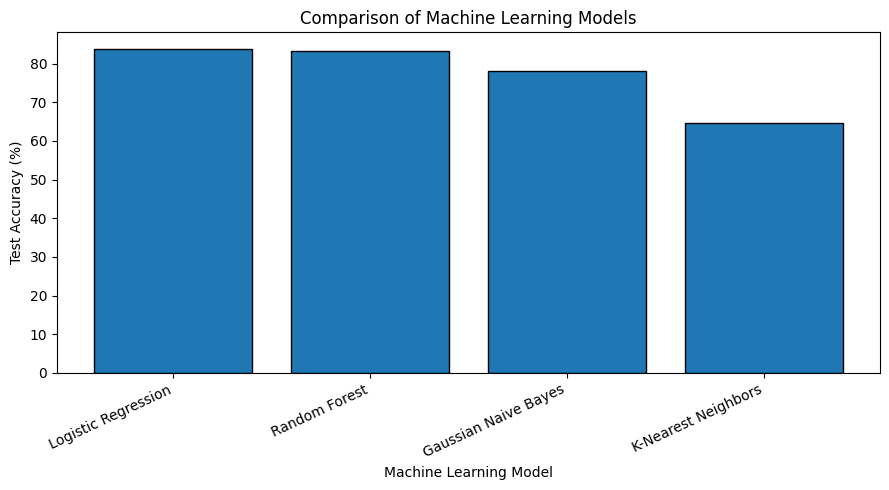

In [30]:
plt.figure(figsize=(9, 5))

plt.bar(
    model_results["Model"],
    model_results["Accuracy (%)"],
    edgecolor="black"
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Test Accuracy (%)")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

## 24. Best Model Selection

We select the model with the highest test accuracy and display
its classification report.

This selection is based on accuracy only.

In [31]:
# Store model predictions
model_predictions = {
    "Logistic Regression": (accuracy1, y_pred1),
    "K-Nearest Neighbors": (accuracy2, y_pred2),
    "Gaussian Naive Bayes": (accuracy3, y_pred3),
    "Random Forest": (accuracy4, y_pred4)
}

# Select model with highest accuracy
best_name = max(
    model_predictions,
    key=lambda name: model_predictions[name][0]
)

best_accuracy, best_predictions = model_predictions[best_name]

print("Best Model:", best_name)
print("Test Accuracy:", round(best_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)

Best Model: Logistic Regression
Test Accuracy: 83.91 %

Classification Report:
              precision    recall  f1-score   support

        High       0.86      0.80      0.83       488
         Low       0.85      0.76      0.80       436
      Medium       0.83      0.89      0.86      1059

    accuracy                           0.84      1983
   macro avg       0.85      0.82      0.83      1983
weighted avg       0.84      0.84      0.84      1983



## 25. Confusion Matrix of the Best Model

The confusion matrix compares actual performance levels with
the levels predicted by the selected model.

It helps identify correct predictions and classification errors.

Confusion Matrix:
[[332 104   0]
 [ 54 943  62]
 [  5  94 389]]


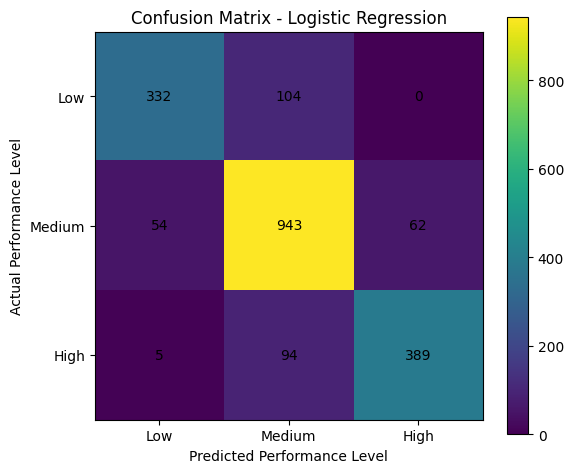

In [32]:
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=["Low", "Medium", "High"]
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

plt.imshow(cm, interpolation="nearest")
plt.title(f"Confusion Matrix - {best_name}")
plt.colorbar()

classes = ["Low", "Medium", "High"]

plt.xticks(range(3), classes)
plt.yticks(range(3), classes)
plt.xlabel("Predicted Performance Level")
plt.ylabel("Actual Performance Level")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

## 26. Conclusion

This project analyzed student exam scores and explored relationships
between academic habits, educational support, and learning environment
factors.

Four classification algorithms were trained and evaluated:
Logistic Regression, K-Nearest Neighbors, Gaussian Naive Bayes,
and Random Forest.

The models were compared using test accuracy, and the highest-accuracy
model was selected for further evaluation using a classification report
and confusion matrix.

The performance categories used in this project are defined specifically
for this analysis and do not represent official academic grades.

The results describe patterns in the available dataset and should not
be interpreted as proof that any individual factor causes changes
in student performance.